In [1]:
# Jiaze Ma and Victor Z
# UW-Madison, 2024
# plastic pyrolysis kinetic model

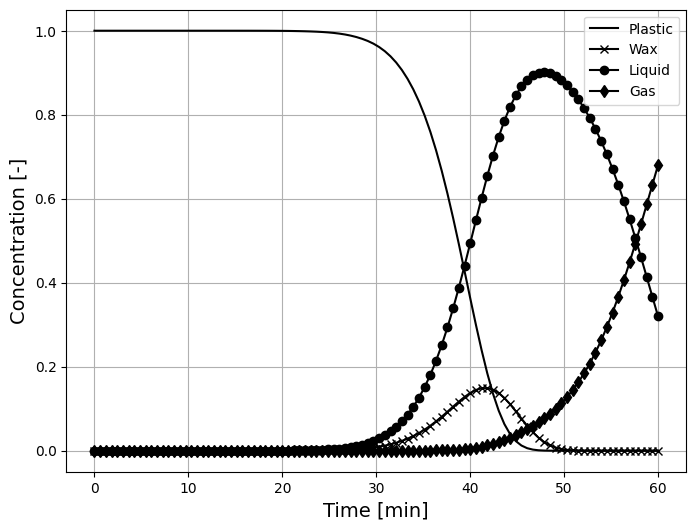

In [2]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

def pyrolysis_model(t, Y, A, E, beta, R):
    P, W, L, G = Y
    T = beta * t + 298.15

    dPdt = -A[0] * np.exp(-E[0] / (R * T)) * P - A[1] * np.exp(-E[1] / (R * T)) * P - A[2] * np.exp(-E[2] / (R * T)) * P
    dWdt =  A[0] * np.exp(-E[0] / (R * T)) * P - A[3] * np.exp(-E[3] / (R * T)) * W - A[5] * np.exp(-E[5] / (R * T)) * W
    dLdt =  A[1] * np.exp(-E[1] / (R * T)) * P + A[3] * np.exp(-E[3] / (R * T)) * W - A[4] * np.exp(-E[4] / (R * T)) * L
    dGdt =  A[2] * np.exp(-E[2] / (R * T)) * P + A[5] * np.exp(-E[5] / (R * T)) * W + A[4] * np.exp(-E[4] / (R * T)) * L

    return [dPdt, dWdt, dLdt, dGdt]

R = 8.314
A = [1.16E+07, 1.52E+07, 7.20E+06, 7.10E+06, 8.70E+06, 1.31E+07]
E = [109, 105, 190, 105, 130, 120]
E = [e * 1000 for e in E]
beta = 10
Y0 = [1.0, 0.0, 0.0, 0.0]

tf = 60
time_span = (0, tf)
time_eval = np.linspace(0, tf, 100)

solution = solve_ivp(pyrolysis_model, time_span, Y0, args=(A, E, beta, R), t_eval=time_eval)

T = solution.t
Y = solution.y

plt.figure(figsize=(8,6))
plt.plot(T, Y[0], 'k-', label='Plastic')
plt.plot(T, Y[1], 'kx-', label='Wax')
plt.plot(T, Y[2], 'ko-', label='Liquid')
plt.plot(T, Y[3], 'kd-', label='Gas')
plt.xlabel('Time [min]', fontsize=14)
plt.ylabel('Concentration [-]', fontsize=14)
plt.legend(loc='upper right')
plt.grid(True)
plt.show()